# Infographix — Feature Engineering v2: Multi-Table Structural, Relational & Demand Representation

**Purpose:** Build the canonical v2 feature representation for conditional scientific poster retrieval, adaptation, and layout generation on **SciPostLayout v2** ($7,855$ posters, $192,697$ element annotations).

---

## 1. Why Redesign Feature Engineering? (Audit of v1 vs. v2)

In `02_feature_engineering.ipynb` (v1), each poster was flattened into a single 92-column vector of category counts, medians, and standard deviations. While useful as an initial exploratory baseline, auditing v1 revealed five structural limitations:

1. **Loss of Individual Elements & Spatial Topology:** Two columns of text and a single central text block can have the exact same `median_center_x = 0.50`. Flattening an entire poster into medians erases column structure, reading order, and element-level geometry.
2. **Duplicate & Misleading Density Features:** `element_density` in v1 was set equal to `element_count` (since normalized canvas area is $1.0$), making it a 100% redundant duplicate. Furthermore, `sum_bbox_area_ratio` summed overlapping boxes without computing the actual **union coverage** (`union_box_coverage`), conflating nested annotations with canvas occupancy.
3. **Zero-Filled Absent Categories:** When a poster had zero `Table` or `List` elements, v1 filled `center_x_table = 0.0` and `area_table = 0.0`, conflating *"category absent"* with *"an element of zero size located at the top-left corner $(0,0)$"*.
4. **Silent Poster Dropping:** Two training posters with a single valid element were dropped due to undefined spread (`NaN`).
5. **No Bridge to Runtime User Input:** A real user provides content blocks (title, authors, paragraphs, figures, tables) rather than bounding-box coordinates.

### The Canonical v2 Multi-Table Data Architecture
Instead of a single flat vector, v2 outputs linked tables under `data/processed/features/v2/` via reusable modules in `src/features/`:
- **`elements.parquet` (Group B):** Preserves all $192,657$ valid element annotations with normalized geometry (`x0, y0, x1, y1, w_norm, h_norm, cx, cy, area_norm`), log-transformed sizes, margin distances, within-poster size ranks, and train-fitted category reference ratios.
- **`relations.parquet` (Group C):** Sparse directed spatial graph ($676,383$ edges) capturing overlap/containment, $k$-NN neighbors, cardinal directional neighbors (`above`, `below`, `left_of`, `right_of`), edge alignment, and figure-caption / section-content spatial hypotheses.
- **`posters.parquet` (Groups A & D):** All $7,855$ posters retained ($0$ dropped) with canvas orientation, category inventories + `has_<category>` flags, quantiles (`p10..p90`), rasterized `union_box_coverage` vs `sum_box_area_fraction`, $4\times 4$ occupancy grids, 16-bin horizontal/vertical projection profiles, peak-detected `estimated_column_count`, gutter fractions, and symmetry scores.
- **`appearance_sample.parquet` (Group E):** Separated pixel-level visual style features (background luminance, colorfulness, edge density, local contrast, visual entropy) so structural models never depend on features unavailable from user text.
- **`PosterRequest` Schema (`src/features/request_schema.py`, Group F):** Runtime content-demand schema with typography-aware text wrapping and candidate compatibility scoring.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.pipeline_v2 import (
    KNOWN_CATEGORY_SLUGS,
    SCIPOST_CATEGORIES,
    run_feature_pipeline_v2,
)
from src.features.request_schema import (
    ContentBlockDemand,
    PosterRequest,
    compute_request_candidate_compatibility,
    estimate_rendered_text_geometry,
    simulate_request_from_heldout_poster,
)

RAW_DIR = PROJECT_ROOT / "data" / "interim" / "scipostlayout" / "poster" / "png"
V2_DIR = PROJECT_ROOT / "data" / "processed" / "features" / "v2"

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
print("Project Root:", PROJECT_ROOT)

Project Root: /home/rahul/Projects/infographix


## 2. Load or Execute the v2 Multi-Table Feature Pipeline & Audit Data Quality

Every preprocessing parameter and reference statistic (`train_category_reference_medians`) is computed **strictly on the training split** (`train`) and applied deterministically to `dev` and `test`. Minor boundary rounding overshoots ($\le 1.0\text{ px}$) are clipped, while genuinely invalid boxes are logged to `rejected_annotations.parquet` with an explicit `rejection_reason`.

In [2]:
if not (V2_DIR / "posters.parquet").exists():
    pipeline_out = run_feature_pipeline_v2(RAW_DIR, V2_DIR, export_legacy=True)
    posters_df = pipeline_out["posters"]
    elements_df = pipeline_out["elements"]
    relations_df = pipeline_out["relations"]
    rejected_df = pipeline_out["rejected"]
    report = pipeline_out["report"]
else:
    posters_df = pd.read_parquet(V2_DIR / "posters.parquet")
    elements_df = pd.read_parquet(V2_DIR / "elements.parquet")
    relations_df = pd.read_parquet(V2_DIR / "relations.parquet")
    rejected_df = pd.read_parquet(V2_DIR / "rejected_annotations.parquet")
    report = json.loads((V2_DIR / "feature_report.json").read_text(encoding="utf-8"))

print("=== CANONICAL V2 TABLE SHAPES ===")
print(f"posters.parquet   : {posters_df.shape[0]:,} posters x {posters_df.shape[1]} columns (0 posters dropped!)")
print(f"elements.parquet  : {elements_df.shape[0]:,} valid elements x {elements_df.shape[1]} columns")
print(f"relations.parquet : {relations_df.shape[0]:,} spatial graph edges x {relations_df.shape[1]} columns")
print(f"rejected.parquet  : {rejected_df.shape[0]:,} rejected annotations logged with explicit reasons")

quality_df = pd.DataFrame(report["quality_summary"]["splits"])
display(quality_df)
print("\nRejection reasons breakdown:", report["quality_summary"]["rejected_by_reason"])

=== CANONICAL V2 TABLE SHAPES ===
posters.parquet   : 7,855 posters x 295 columns (0 posters dropped!)
elements.parquet  : 192,657 valid elements x 44 columns
relations.parquet : 676,383 spatial graph edges x 27 columns
rejected.parquet  : 40 rejected annotations logged with explicit reasons


,split,total_posters,posters_retained,posters_with_valid_elements,total_annotations,valid_annotations,rejected_annotations
0,train,6855,6855,6854,168313,168276,37
1,dev,500,500,500,12141,12140,1
2,test,500,500,500,12243,12241,2



Rejection reasons breakdown: {'exceeds_canvas_bounds': 37, 'non_positive_dimensions': 3}


## 3. Group B: Element-Level Features (`elements.parquet`)

Preserving every annotated region as an individual record is essential for layout adaptation and future Set Transformer / GNN layout generators. Notice how each element stores:
- Normalized coordinates (`x0, y0, x1, y1, w_norm, h_norm, cx, cy, area_norm`) and log-transformed dimensions (`log_w_norm, log_h_norm, log_area_norm, log_bbox_aspect_ratio`).
- Edge margins (`left_margin, right_margin, top_margin, bottom_margin`).
- Hierarchy descriptors (`poster_area_rank_pct`, `category_area_rank_pct`, `is_top3_largest`).
- Leak-free training-normalized ratios (`ratio_area_to_train_cat_median`).

In [3]:
sample_el_cols = [
    "poster_id", "element_id", "split", "category_slug",
    "x0", "y0", "w_norm", "h_norm", "cx", "cy", "area_norm",
    "log_bbox_aspect_ratio", "poster_area_rank_pct",
    "ratio_area_to_train_cat_median", "horiz_zone", "vert_zone", "grid_4x4_cell"
]
display(elements_df[sample_el_cols].head(8).round(4))

print("\nTraining-Split Reference Category Medians (Normalized Width, Height, Area):")
ref_med_df = pd.DataFrame(report["quality_summary"]["train_category_reference_medians"]).T
display(ref_med_df.round(4))

,poster_id,element_id,split,category_slug,x0,y0,w_norm,h_norm,cx,cy,area_norm,log_bbox_aspect_ratio,poster_area_rank_pct,ratio_area_to_train_cat_median,horiz_zone,vert_zone,grid_4x4_cell
0,2921933168,22251,train,title,0.2219,0.0640,0.5472,0.0373,0.4955,0.0826,0.0204,2.6865,0.900,0.5835,center,top,1
1,2921933168,22252,train,author_info,0.3087,0.1126,0.3543,0.0232,0.4859,0.1243,0.0082,2.7240,0.675,0.3061,center,top,1
2,2921933168,22253,train,section,0.5129,0.1653,0.2538,0.0140,0.6397,0.1723,0.0036,2.8949,0.350,2.4051,center,top,2
3,2921933168,22254,train,section,0.0686,0.1657,0.3909,0.0272,0.2641,0.1793,0.0106,2.6655,0.800,7.1779,left,top,1
4,2921933168,22255,train,text,0.0661,0.2004,0.4163,0.2451,0.2743,0.3229,0.1021,0.5296,1.000,6.6261,left,upper_mid,5
5,2921933168,22256,train,section,0.0680,0.4661,0.1197,0.0140,0.1279,0.4731,0.0017,2.1438,0.150,1.1349,left,upper_mid,4
6,2921933168,22257,train,text,0.5160,0.1986,0.3127,0.0132,0.6723,0.2052,0.0041,3.1683,0.450,0.2671,right,top,2
7,2921933168,22258,train,text,0.5116,0.2262,0.0813,0.0500,0.5523,0.2512,0.0041,0.4859,0.425,0.2638,center,upper_mid,6



Training-Split Reference Category Medians (Normalized Width, Height, Area):


,w_norm,h_norm,area_norm
author_info,0.6329,0.0446,0.0269
caption,0.2195,0.0188,0.0045
figure,0.2358,0.1355,0.0326
list,0.2890,0.0807,0.0241
section,0.1044,0.0138,0.0015
table,0.2895,0.1190,0.0341
text,0.2826,0.0512,0.0154
title,0.7153,0.0494,0.0350
unknown,0.1054,0.1782,0.0390


## 4. Group C: Pairwise Spatial Relationships (`relations.parquet`)

To distinguish layouts that share similar global counts but arrange elements differently, `relations.parquet` builds a sparse graph per poster connecting:
1. Overlapping or contained boxes (`overlap`).
2. Top-$3$ nearest neighbors (`knn`).
3. Nearest directional neighbors in the same column or row (`nearest_below_col`, `nearest_right_row`).
4. Spatial domain hypotheses (`figure_caption_hypothesis`).

In [4]:
rel_sample_cols = [
    "poster_id", "source_element_id", "target_element_id",
    "source_category", "target_category", "dx", "dy", "distance",
    "horizontal_gap", "vertical_gap", "iou",
    "aligned_left", "same_column_hypothesis", "direction", "edge_types"
]
display(relations_df[rel_sample_cols].head(8).round(4))

print("\nTop Spatial Edge Types in relations.parquet:")
display(relations_df["edge_types"].value_counts().head(10).to_frame("edge_count"))

,poster_id,source_element_id,target_element_id,source_category,target_category,dx,dy,distance,horizontal_gap,vertical_gap,iou,aligned_left,same_column_hypothesis,direction,edge_types
0,2921933168,22251,22252,title,author_info,-0.0096,0.0417,0.0428,-0.4411,0.0114,0.0,False,True,below,"knn,nearest_below_col"
1,2921933168,22251,22253,title,section,0.1443,0.0897,0.1699,-0.2562,0.0640,0.0,False,True,right_of,knn
2,2921933168,22251,22258,title,text,0.0568,0.1686,0.1779,-0.2575,0.1250,0.0,False,True,below,knn
3,2921933168,22252,22251,author_info,title,0.0096,-0.0417,0.0428,-0.4411,0.0114,0.0,False,True,above,knn
4,2921933168,22252,22258,author_info,text,0.0664,0.1270,0.1433,-0.1514,0.0903,0.0,False,True,below,"knn,nearest_below_col"
5,2921933168,22252,22253,author_info,section,0.1539,0.0480,0.1612,-0.1501,0.0294,0.0,False,True,right_of,knn
6,2921933168,22253,22257,section,text,0.0326,0.0329,0.0463,-0.2507,0.0193,0.0,True,True,below,"knn,nearest_below_col"
7,2921933168,22253,22259,section,figure,0.0357,0.0877,0.0947,-0.1626,0.0421,0.0,False,True,below,knn



Top Spatial Edge Types in relations.parquet:


,edge_count
edge_types,
knn,391258
"knn,nearest_below_col",149854
nearest_right_row,84536
"knn,nearest_right_row",17760
nearest_below_col,11138
"figure_caption_hypothesis,knn,nearest_below_col",8986
"figure_caption_hypothesis,knn",5262
"knn,overlap",1900
figure_caption_hypothesis,1059


## 5. Groups A & D: Poster-Level & Global Composition Features (`posters.parquet`)

Let's inspect the distribution of key structural features engineered in v2:
- **Orientation (`portrait`, `landscape`, `square`)** and continuous `log_aspect_ratio`.
- **Corrected Coverage Metrics:** Comparing `sum_box_area_fraction` (which can exceed $1.0$ due to overlapping annotations) against true rasterized `union_box_coverage` ($\in [0, 1]$) and `overlap_excess`.
- **Structural Column Detection (`estimated_column_count`):** Derived from peak and valley analysis on the smoothed 1D horizontal body occupancy profile.

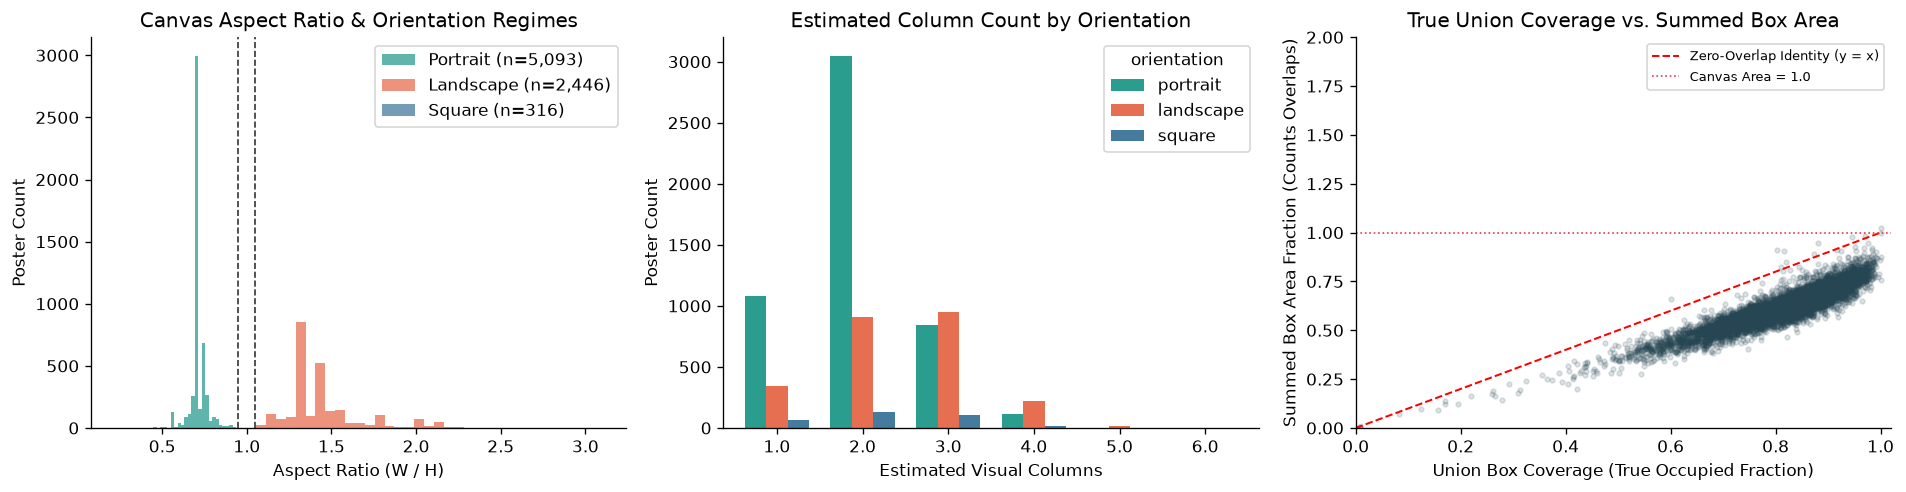

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. Aspect Ratio & Orientation Separation
for orient, col in [("portrait", "#2a9d8f"), ("landscape", "#e76f51"), ("square", "#457b9d")]:
    sub = posters_df[posters_df["orientation"] == orient]
    axes[0].hist(sub["aspect_ratio"], bins=35, alpha=0.75, label=f"{orient.title()} (n={len(sub):,})", color=col)
axes[0].axvline(0.95, color="#333", linestyle="--", lw=1)
axes[0].axvline(1.05, color="#333", linestyle="--", lw=1)
axes[0].set_title("Canvas Aspect Ratio & Orientation Regimes")
axes[0].set_xlabel("Aspect Ratio (W / H)")
axes[0].set_ylabel("Poster Count")
axes[0].legend()

# 2. Estimated Column Count by Orientation
col_ct = pd.crosstab(posters_df["estimated_column_count"], posters_df["orientation"])[["portrait", "landscape", "square"]]
col_ct.plot(kind="bar", ax=axes[1], color=["#2a9d8f", "#e76f51", "#457b9d"], width=0.75)
axes[1].set_title("Estimated Column Count by Orientation")
axes[1].set_xlabel("Estimated Visual Columns")
axes[1].set_ylabel("Poster Count")
axes[1].tick_params(axis="x", rotation=0)

# 3. Summed Box Area vs True Union Box Coverage
axes[2].scatter(
    posters_df["union_box_coverage"],
    posters_df["sum_box_area_fraction"],
    alpha=0.15, s=8, color="#264653"
)
axes[2].plot([0, 1], [0, 1], "r--", lw=1.2, label="Zero-Overlap Identity (y = x)")
axes[2].axhline(1.0, color="#e63946", linestyle=":", lw=1, label="Canvas Area = 1.0")
axes[2].set_xlim(0, 1.02)
axes[2].set_ylim(0, 2.0)
axes[2].set_title("True Union Coverage vs. Summed Box Area")
axes[2].set_xlabel("Union Box Coverage (True Occupied Fraction)")
axes[2].set_ylabel("Summed Box Area Fraction (Counts Overlaps)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 6. Visual Validation: Diagnostic Overlays of Layouts, Spatial Graphs, Profiles & Occupancy Grids

Following Step 5 of `infographix_feature_engineering_spec.md`, we visually inspect representative posters across **Portrait 2-Column**, **Portrait 3-Column**, **Landscape 3-Column**, and **Landscape 4-Column (Figure-Heavy)** structures. For each poster we display:
1. **Bounding boxes colored by semantic category** + element centers and **spatial graph edges** (green dashed lines = `figure_caption_hypothesis` or `nearest_below_col`).
2. **16-bin horizontal occupancy profile** showing how vertical column peaks and gutters are detected.
3. **$4\times 4$ spatial occupancy grid heatmap** used for fast structural retrieval and MMR diversity reranking.

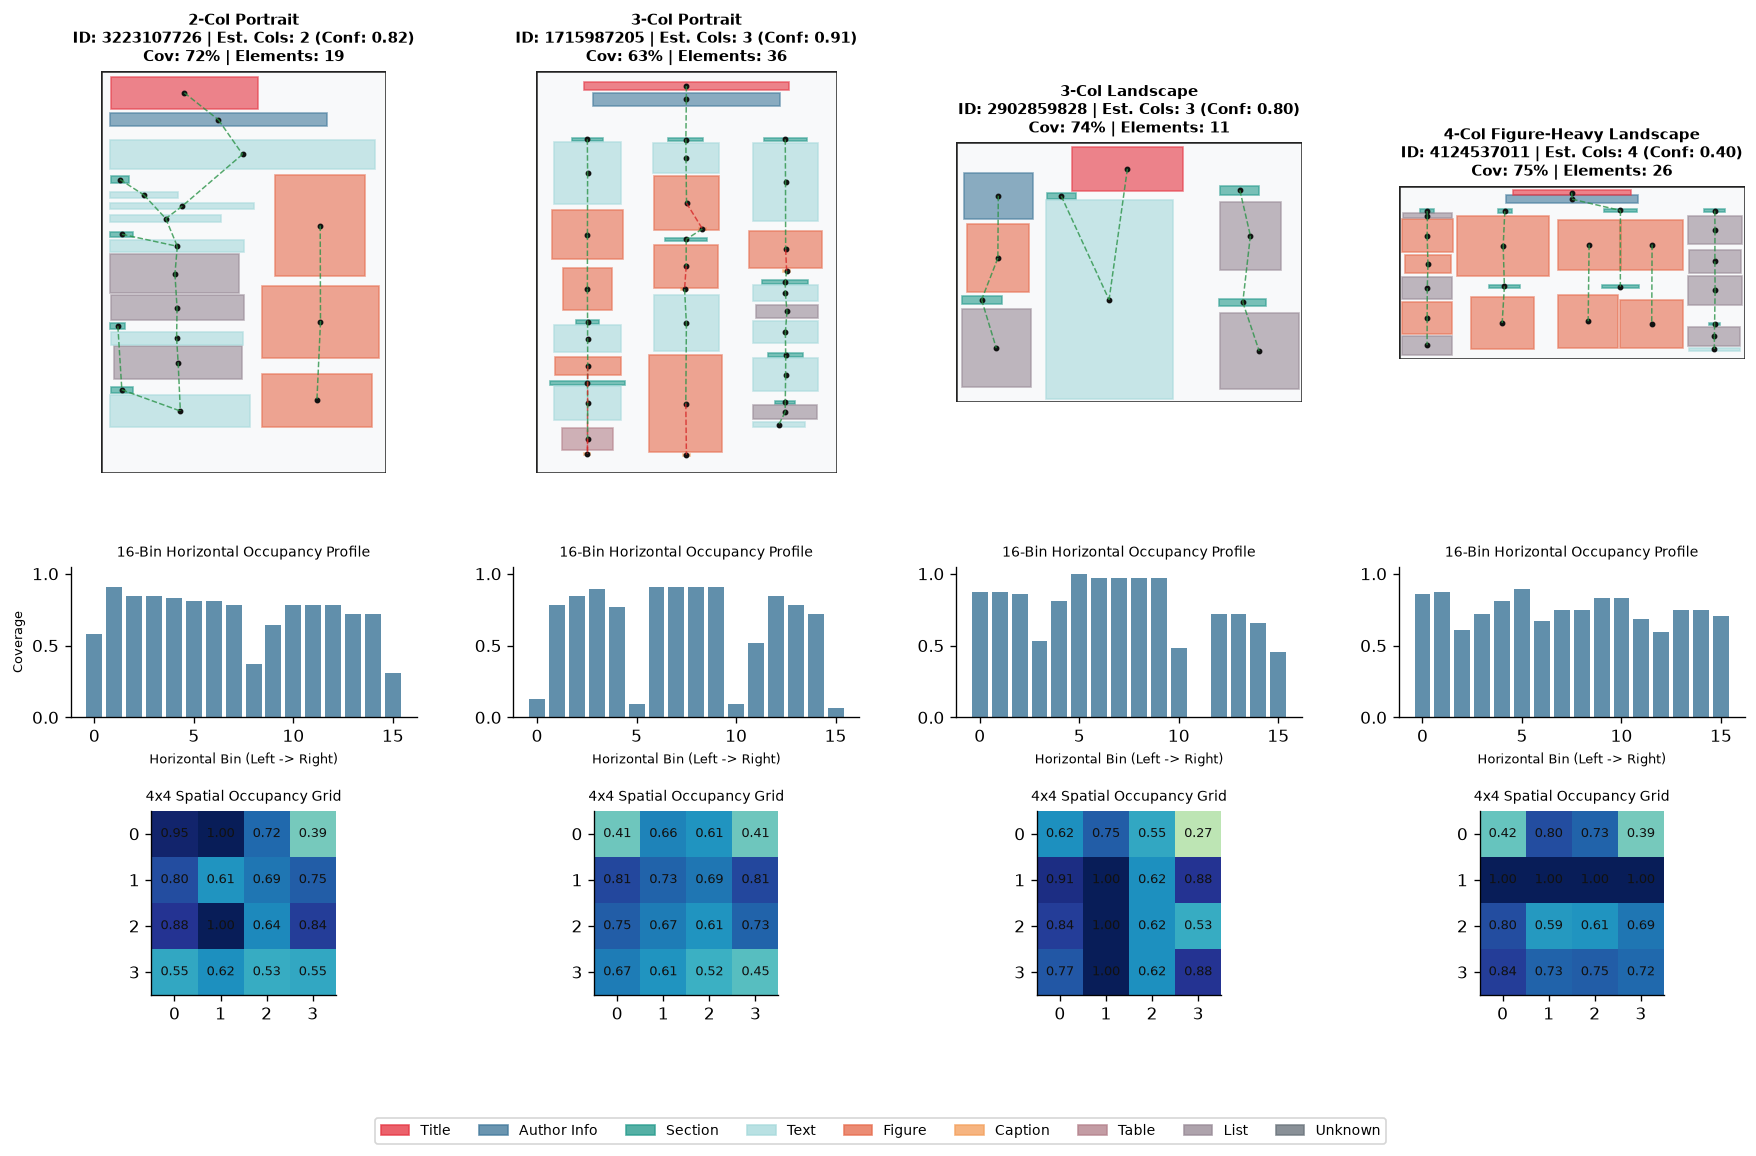

In [6]:
CAT_COLORS = {
    "title": "#e63946",
    "author_info": "#457b9d",
    "section": "#2a9d8f",
    "text": "#a8dadc",
    "figure": "#e76f51",
    "caption": "#f4a261",
    "table": "#b5838d",
    "list": "#9a8c98",
    "unknown": "#6c757d",
}

# Pick 4 distinct structural examples from train/test
ex_2col_port = posters_df[(posters_df["orientation"] == "portrait") & (posters_df["estimated_column_count"] == 2) & (posters_df["column_assignment_confidence"] > 0.75)].iloc[0]
ex_3col_port = posters_df[(posters_df["orientation"] == "portrait") & (posters_df["estimated_column_count"] == 3) & (posters_df["column_assignment_confidence"] > 0.75)].iloc[0]
ex_3col_land = posters_df[(posters_df["orientation"] == "landscape") & (posters_df["estimated_column_count"] == 3) & (posters_df["column_assignment_confidence"] > 0.75)].iloc[0]
ex_4col_land = posters_df[(posters_df["orientation"] == "landscape") & (posters_df["estimated_column_count"] == 4) & (posters_df["count_figure"] >= 5)].iloc[0]

examples = [
    ("2-Col Portrait", ex_2col_port),
    ("3-Col Portrait", ex_3col_port),
    ("3-Col Landscape", ex_3col_land),
    ("4-Col Figure-Heavy Landscape", ex_4col_land),
]

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(3, 4, height_ratios=[2.4, 0.9, 1.1], hspace=0.38, wspace=0.28)

for col_idx, (title_label, p_row) in enumerate(examples):
    pid = int(p_row["poster_id"])
    p_els = elements_df[elements_df["poster_id"] == pid]
    p_rels = relations_df[relations_df["poster_id"] == pid]

    # Row 0: Bounding Boxes + Spatial Relational Graph Overlay
    ax_box = fig.add_subplot(gs[0, col_idx])
    W, H = p_row["canvas_width_px"], p_row["canvas_height_px"]
    ax_box.set_xlim(0, 1)
    ax_box.set_ylim(1, 0)
    ax_box.set_aspect(H / W)
    ax_box.axis("off")
    ax_box.add_patch(patches.Rectangle((0, 0), 1, 1, fill=True, color="#f8f9fa", ec="#222", lw=1.5))

    el_centers = {int(r["element_id"]): (float(r["cx"]), float(r["cy"])) for _, r in p_els.iterrows()}
    for _, r in p_els.iterrows():
        c_slug = str(r["category_slug"])
        col = CAT_COLORS.get(c_slug, "#888")
        ax_box.add_patch(
            patches.Rectangle(
                (r["x0"], r["y0"]), r["w_norm"], r["h_norm"],
                fill=True, color=col, alpha=0.62, ec=col, lw=1.0
            )
        )
        ax_box.plot(r["cx"], r["cy"], "o", color="#111", markersize=2.5)

    # Plot directional/pairing graph edges
    for _, edge in p_rels.iterrows():
        if "nearest_below_col" in edge["edge_types"] or "figure_caption_hypothesis" in edge["edge_types"]:
            s_id, t_id = int(edge["source_element_id"]), int(edge["target_element_id"])
            if s_id in el_centers and t_id in el_centers:
                x_s, y_s = el_centers[s_id]
                x_t, y_t = el_centers[t_id]
                edge_col = "#d62828" if "figure_caption" in edge["edge_types"] else "#2b9348"
                ax_box.plot([x_s, x_t], [y_s, y_t], "--", color=edge_col, lw=0.9, alpha=0.8)

    ax_box.set_title(
        f"{title_label}\nID: {pid} | Est. Cols: {int(p_row['estimated_column_count'])} (Conf: {p_row['column_assignment_confidence']:.2f})\n"
        f"Cov: {p_row['union_box_coverage']:.0%} | Elements: {int(p_row['known_element_count'])}",
        fontsize=9, fontweight="bold"
    )

    # Row 1: 16-bin Horizontal Occupancy Profile
    ax_prof = fig.add_subplot(gs[1, col_idx])
    h_vals = [p_row[f"horiz_occ_{b:02d}"] for b in range(16)]
    ax_prof.bar(range(16), h_vals, color="#457b9d", alpha=0.85, width=0.8)
    ax_prof.set_ylim(0, 1.05)
    ax_prof.set_title("16-Bin Horizontal Occupancy Profile", fontsize=8.5)
    ax_prof.set_xlabel("Horizontal Bin (Left -> Right)", fontsize=7.5)
    if col_idx == 0:
        ax_prof.set_ylabel("Coverage", fontsize=8)

    # Row 2: 4x4 Spatial Occupancy Grid Heatmap
    ax_grid = fig.add_subplot(gs[2, col_idx])
    grid_mat = np.array([[p_row[f"occ_grid_r{r}_c{c}"] for c in range(4)] for r in range(4)])
    im = ax_grid.imshow(grid_mat, cmap="YlGnBu", vmin=0, vmax=1)
    for r in range(4):
        for c in range(4):
            ax_grid.text(c, r, f"{grid_mat[r, c]:.2f}", ha="center", va="center", fontsize=7.5, color="#111")
    ax_grid.set_xticks(range(4))
    ax_grid.set_yticks(range(4))
    ax_grid.set_title("4x4 Spatial Occupancy Grid", fontsize=8.5)

legend_patches = [patches.Patch(color=col, label=cat.replace("_", " ").title(), alpha=0.8) for cat, col in CAT_COLORS.items()]
fig.legend(handles=legend_patches, loc="lower center", ncol=9, fontsize=8.5, bbox_to_anchor=(0.5, -0.02))
plt.show()

## 7. Group E: Visual Appearance & Design Style Features (`appearance_sample.parquet`)

Kept strictly decoupled from the structural geometry tables so that layout models never depend on image pixels at runtime, `appearance_sample.parquet` extracts background luminance, Hasler-Süsstrunk colorfulness, edge density, local contrast, and Shannon entropy from the poster PNGs.

Loaded 180 visual appearance records across splits:


,mean_luminance,std_luminance,mean_saturation,std_saturation,colorfulness_index,bg_r,bg_g,bg_b,bg_luminance,is_dark_background,edge_density,local_contrast,visual_entropy,text_region_contrast,figure_region_colorfulness,poster_id,file_name,split
0,0.8659,0.1723,0.1036,0.2215,0.1805,1.0000,1.0000,1.0000,1.0000,0.0,0.3800,0.1318,3.3585,0.0816,0.1272,2864343044,16555.png,train
1,0.8240,0.2332,0.1848,0.3002,0.2297,0.9333,0.9490,0.9686,0.9471,0.0,0.3366,0.1351,3.3460,0.0997,0.1702,4037940113,21469.png,train
2,0.7675,0.2090,0.1527,0.2450,0.1736,0.7412,0.7294,0.7882,0.7362,0.0,0.3935,0.1770,3.9846,0.1331,0.1227,2145400738,13183.png,train
3,0.8191,0.1679,0.3204,0.3092,0.4080,1.0000,1.0000,1.0000,1.0000,0.0,0.2731,0.0981,3.5054,0.0797,0.0337,2812551734,11311.png,train
4,0.6993,0.1858,0.4087,0.3420,0.4321,0.6431,0.7373,0.6392,0.7102,0.0,0.4068,0.1443,3.9886,0.0965,0.1207,1024733204,10787.png,train
5,0.8038,0.1978,0.1819,0.2954,0.3166,0.2824,0.5020,0.9765,0.4895,0.0,0.3832,0.1805,3.2913,0.1253,0.2024,3888719739,14514.png,train


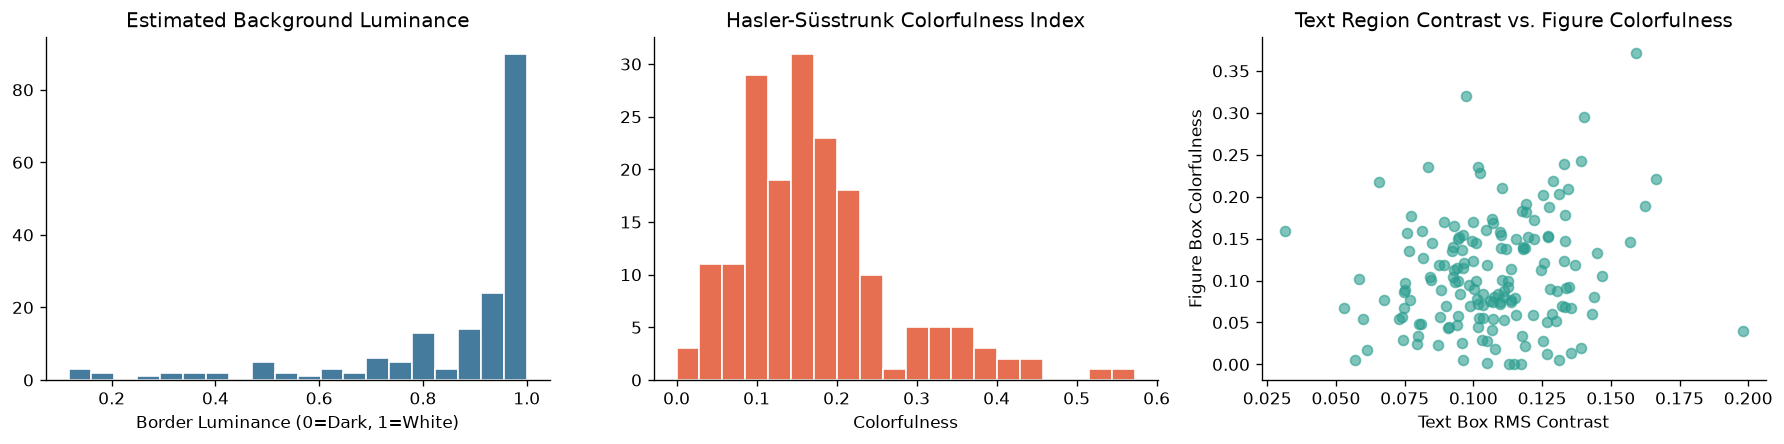

In [7]:
app_df = pd.read_parquet(V2_DIR / "appearance_sample.parquet")
print(f"Loaded {len(app_df)} visual appearance records across splits:")
display(app_df.head(6).round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(app_df["bg_luminance"], bins=20, color="#457b9d", edgecolor="white")
axes[0].set_title("Estimated Background Luminance")
axes[0].set_xlabel("Border Luminance (0=Dark, 1=White)")

axes[1].hist(app_df["colorfulness_index"], bins=20, color="#e76f51", edgecolor="white")
axes[1].set_title("Hasler-Süsstrunk Colorfulness Index")
axes[1].set_xlabel("Colorfulness")

axes[2].scatter(app_df["text_region_contrast"], app_df["figure_region_colorfulness"], alpha=0.6, color="#2a9d8f")
axes[2].set_title("Text Region Contrast vs. Figure Colorfulness")
axes[2].set_xlabel("Text Box RMS Contrast")
axes[2].set_ylabel("Figure Box Colorfulness")
plt.tight_layout()
plt.show()

## 8. Group F: Bridging User Content Specifications (`PosterRequest`) to Dataset Layouts

At inference time, a user provides **content blocks** (word counts, image aspect ratios, table rows/columns) rather than bounding boxes. `src/features/request_schema.py` provides:
1. `estimate_rendered_text_geometry()`: Wraps text at a candidate column width to compute line count and normalized height demand.
2. `PosterRequest.to_summary_dict()`: Maps user content blocks into the exact structural demand vocabulary of `posters.parquet`.
3. `compute_request_candidate_compatibility()`: Evaluates canvas match, category inventory shortfall/surplus, visual/textual capacity match, and column alignment.

In [8]:
# Demonstrate runtime typography-aware text sizing across 2-column vs 3-column widths
for col_w, label in [(0.44, "2-Column Width (44% canvas)"), (0.28, "3-Column Width (28% canvas)")]:
    est = estimate_rendered_text_geometry(word_count=140, candidate_col_width_norm=col_w)
    print(f"{label} -> Est. Lines: {int(est['estimated_lines'])}, Pref Width: {est['preferred_width']:.2f}, Pref Height: {est['preferred_height']:.2f}, Area: {est['preferred_area_norm']:.4f}")

# Construct a realistic user content specification
user_request = PosterRequest(
    request_id="demo_ml_paper_01",
    requested_aspect_ratio=1.414,
    preferred_column_count=3,
    blocks=[
        ContentBlockDemand("b_title", "title", "title", preferred_width=0.80, preferred_height=0.06),
        ContentBlockDemand("b_auth", "authors", "author_info", preferred_width=0.70, preferred_height=0.04),
        ContentBlockDemand("s_intro", "intro_heading", "section", preferred_width=0.28, preferred_height=0.02),
        ContentBlockDemand("t_intro", "introduction", "text", **estimate_rendered_text_geometry(word_count=120, candidate_col_width_norm=0.28)),
        ContentBlockDemand("s_meth", "methods_heading", "section", preferred_width=0.28, preferred_height=0.02),
        ContentBlockDemand("t_meth", "methods", "text", **estimate_rendered_text_geometry(word_count=160, candidate_col_width_norm=0.28)),
        ContentBlockDemand("f_arch", "architecture_diagram", "figure", aspect_ratio=1.6, preferred_width=0.30, preferred_height=0.19),
        ContentBlockDemand("c_arch", "arch_caption", "caption", preferred_width=0.28, preferred_height=0.025),
        ContentBlockDemand("s_res", "results_heading", "section", preferred_width=0.28, preferred_height=0.02),
        ContentBlockDemand("f_plot", "results_plot", "figure", aspect_ratio=1.3, preferred_width=0.28, preferred_height=0.21),
        ContentBlockDemand("c_plot", "plot_caption", "caption", preferred_width=0.28, preferred_height=0.025),
        ContentBlockDemand("tbl_1", "benchmark_table", "table", table_rows=8, table_cols=5, preferred_width=0.28, preferred_height=0.14),
        ContentBlockDemand("t_conc", "conclusion", "text", **estimate_rendered_text_geometry(word_count=90, candidate_col_width_norm=0.28)),
    ],
)

print("\nGenerated Request Demand Summary Vector:")
req_summary = user_request.to_summary_dict()
for k in ["orientation", "aspect_ratio", "estimated_column_count", "known_element_count", "visual_element_count", "textual_element_count", "visual_area_sum", "textual_area_sum"]:
    print(f"  {k:25s}: {req_summary[k]}")

2-Column Width (44% canvas) -> Est. Lines: 10, Pref Width: 0.44, Pref Height: 0.20, Area: 0.0866
3-Column Width (28% canvas) -> Est. Lines: 16, Pref Width: 0.28, Pref Height: 0.31, Area: 0.0866

Generated Request Demand Summary Vector:
  orientation              : landscape
  aspect_ratio             : 1.414
  estimated_column_count   : 3
  known_element_count      : 13
  visual_element_count     : 3
  textual_element_count    : 5
  visual_area_sum          : 0.155
  textual_area_sum         : 0.24752777777777785
